# Independent-variable correlation and multicollinearity analysis

This notebook uses the M4 independent variables from `question_b_feature_dictionary.csv`. It reports Pearson pairwise correlations, a correlation heatmap, highly correlated feature pairs, and variance inflation factors (VIF).

The target `ac_load_kw` is intentionally excluded. The analysis uses the modelling rows with `split == 'train'` so that the diagnostic is based on the fitting period and does not use held-out test information.

Rules of thumb: absolute correlation >= 0.80 is a strong pairwise warning; VIF >= 5 indicates possible multicollinearity and VIF >= 10 indicates a serious warning. Tree models such as XGBoost can still train with correlated variables, but correlated features can make feature importance and SHAP attribution less stable.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if ROOT.name != '4-XGBoost':
    ROOT = next(p for p in [ROOT, *ROOT.parents] if p.name == '4-XGBoost')
DATA_DIR = ROOT.parent / 'cleaned_data'
OUTPUT_DIR = ROOT / 'outputs' / 'multicollinearity'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('Data folder:', DATA_DIR)
print('Output folder:', OUTPUT_DIR)

Data folder: /Users/wzc/Desktop/SMU/Y3T1/IS4001 Smart Building Analytics/project/git/is4001/Qn_B/cleaned_data
Output folder: /Users/wzc/Desktop/SMU/Y3T1/IS4001 Smart Building Analytics/project/git/is4001/Qn_B/4-XGBoost/outputs/multicollinearity


## 1. Load the training data and select M4 variables

In [3]:
data = pd.read_parquet(DATA_DIR / 'question_b_model_data.parquet')
dictionary = pd.read_csv(DATA_DIR / 'question_b_feature_dictionary.csv')
features = dictionary.loc[dictionary['M4'].eq('Yes'), 'column'].tolist()
train = data.loc[data['split'].eq('train'), features].copy()
numeric_features = train.select_dtypes(include=np.number).columns.tolist()
train = train[numeric_features]
print(f'Training rows: {len(train):,}')
print(f'Independent variables: {len(numeric_features)}')
display(pd.DataFrame({'feature': numeric_features, 'missing_values': train.isna().sum().values}))

Training rows: 111,779
Independent variables: 24


,feature,missing_values
0,floor,0
1,zone_code,0
2,hour,0
3,weekday,0
4,month,0
5,is_weekend,0
6,is_holiday,0
7,ac_load_kw_yesterday,912
8,ac_load_kw_2_days_ago,1560
9,ac_load_kw_last_week,4437


## 2. Pearson correlation heatmap

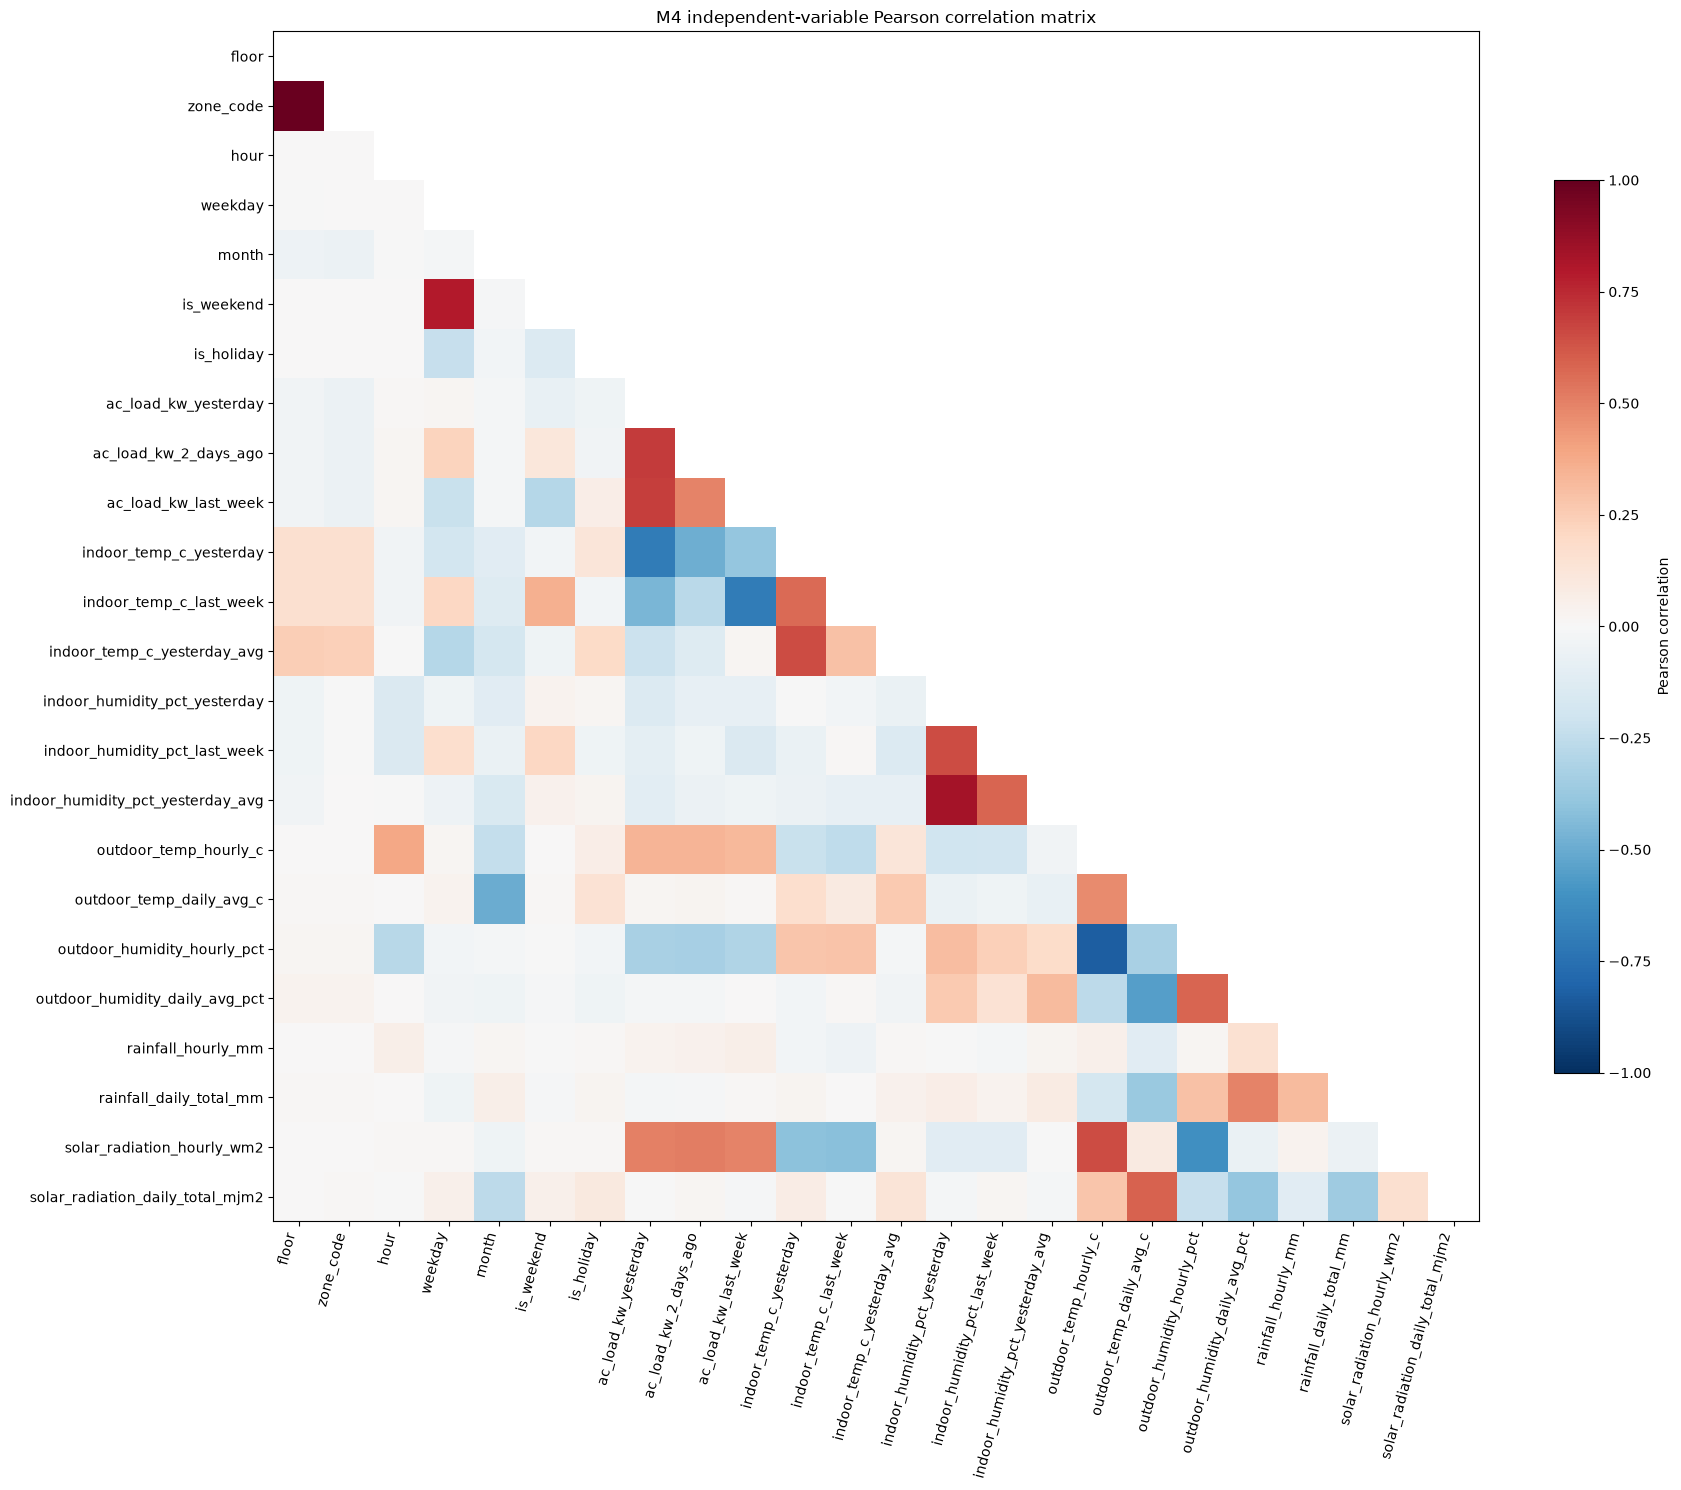

In [5]:
correlation = train.corr(method='pearson', min_periods=100)
correlation.to_csv(OUTPUT_DIR / 'm4_correlation_matrix.csv')
plt.figure(figsize=(18, 15))
mask = np.triu(np.ones_like(correlation, dtype=bool))
heatmap = np.ma.masked_where(mask, correlation.to_numpy())
image = plt.imshow(heatmap, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')
plt.colorbar(image, label='Pearson correlation', shrink=0.75)
plt.title('M4 independent-variable Pearson correlation matrix')
plt.xticks(range(len(correlation.columns)), correlation.columns, rotation=75, ha='right')
plt.yticks(range(len(correlation.index)), correlation.index)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'm4_correlation_heatmap.png', dpi=200)
plt.show()

## 3. Highly correlated feature pairs

This table removes the diagonal and duplicate mirrored pairs. Review these pairs before interpreting individual feature importance values.

In [ ]:
pairs = correlation.where(np.triu(np.ones(correlation.shape), k=1).astype(bool))
high_pairs = (
    pairs.stack().rename('correlation').reset_index()
    .rename(columns={'level_0': 'feature_1', 'level_1': 'feature_2'})
)
high_pairs['abs_correlation'] = high_pairs['correlation'].abs()
high_pairs = high_pairs.sort_values('abs_correlation', ascending=False)
high_pairs.to_csv(OUTPUT_DIR / 'm4_high_correlation_pairs.csv', index=False)
print('Pairs with absolute correlation >= 0.80:')
display(high_pairs.loc[high_pairs['abs_correlation'].ge(0.80)].head(50).round(4))

Pairs with absolute correlation >= 0.80:


,feature_1,feature_2,correlation,abs_correlation
1,floor,zone_code,0.9869,0.9869
327,indoor_humidity_pct_yesterday,indoor_humidity_pct_yesterday_avg,0.8298,0.8298
402,outdoor_temp_hourly_c,outdoor_humidity_hourly_pct,-0.8281,0.8281


## 4. Variance inflation factor (VIF)

VIF is calculated after median-imputing missing values and standardizing each variable. It is a diagnostic only; the XGBoost training pipeline still handles missing values natively and does not use this imputed matrix.

In [ ]:
def calculate_vif(frame):
    values = frame.astype(float).copy()
    values = values.fillna(values.median())
    means = values.mean()
    std = values.std(ddof=0).replace(0, 1)
    z = ((values - means) / std).to_numpy()
    result = []
    for index, feature in enumerate(values.columns):
        other = np.delete(z, index, axis=1)
        target = z[:, index]
        coefficients, *_ = np.linalg.lstsq(other, target, rcond=None)
        fitted = other @ coefficients
        residual = target - fitted
        r_squared = 1 - np.sum(residual ** 2) / np.sum((target - target.mean()) ** 2)
        vif = np.inf if r_squared >= 1 - 1e-12 else 1 / (1 - r_squared)
        result.append({'feature': feature, 'vif': vif, 'r_squared_from_other_features': r_squared})
    return pd.DataFrame(result).sort_values('vif', ascending=False)

vif = calculate_vif(train)
vif.to_csv(OUTPUT_DIR / 'm4_vif.csv', index=False)
display(vif.round(4))
print('\nVIF >= 5:')
display(vif.loc[vif['vif'].ge(5)].round(4))

,feature,vif,r_squared_from_other_features
0,floor,43.3841,0.9770
1,zone_code,43.3291,0.9769
18,outdoor_humidity_hourly_pct,15.3039,0.9347
16,outdoor_temp_hourly_c,14.6353,0.9317
19,outdoor_humidity_daily_avg_pct,7.3020,0.8631
17,outdoor_temp_daily_avg_c,6.2937,0.8411
7,ac_load_kw_yesterday,4.2958,0.7672
10,indoor_temp_c_yesterday,3.9143,0.7445
3,weekday,3.6504,0.7261
9,ac_load_kw_last_week,3.5021,0.7145



VIF >= 5:


,feature,vif,r_squared_from_other_features
0,floor,43.3841,0.9770
1,zone_code,43.3291,0.9769
18,outdoor_humidity_hourly_pct,15.3039,0.9347
16,outdoor_temp_hourly_c,14.6353,0.9317
19,outdoor_humidity_daily_avg_pct,7.3020,0.8631
17,outdoor_temp_daily_avg_c,6.2937,0.8411


## 5. Interpretation guide

- High correlation between lagged or daily-average variables is expected because they describe related time periods.
- For XGBoost, multicollinearity usually does not invalidate prediction because trees can choose among correlated predictors.
- It can dilute gain-based importance and distribute SHAP attribution across correlated variables, so interpret groups of related features together.
- Do not remove variables solely because of correlation without checking validation performance. If a reduced feature set is desired, retrain and compare it using the same validation and test protocol.

Saved outputs: `m4_correlation_matrix.csv`, `m4_correlation_heatmap.png`, `m4_high_correlation_pairs.csv`, and `m4_vif.csv`.